# Semaine 8 — Conception de filtres RIF (FIR)

**Approche pratique** : la théorie des filtres à réponse impulsionnelle finie est **mise en œuvre** sur des cas concrets — audio, ECG, image, démodulation. On mesure à chaque fois le **compromis fenêtre ↔ atténuation ↔ largeur de transition**, et on montre pourquoi la **phase linéaire** est la vraie raison d'utiliser un FIR.

> 🎯 **Fil rouge** : *un filtre FIR ne sert pas à « être plus simple » qu'un IIR — il sert à garantir une phase linéaire et une stabilité absolue. On le choisit pour cela, pas pour le plaisir.*

# Objectifs d'apprentissage

À l'issue de cette semaine, l'étudiant sera capable de :

- **Distinguer** filtres FIR et IIR (avantages/inconvénients réels).
- **Concevoir** un filtre FIR par la **méthode des fenêtres** (rect, Hann, Hamming, Blackman, Kaiser).
- **Choisir** la fenêtre selon le compromis **lobe principal / lobes secondaires** et la contrainte CPU.
- **Vérifier** la **linéarité de phase** et le **retard de groupe** $\tau_g = (N-1)/2$.
- **Appliquer** un FIR anti-repliement à un signal **audio sous-échantillonné**.
- **Concevoir** un **réjecteur 50 Hz FIR** sur un **ECG** et le comparer à un IIR.
- **Implémenter** un **flou d'image séparable** (gain O(N²) → O(2N)).
- **Extraire une enveloppe AM** avec un **filtre de Hilbert FIR**.
- **Utiliser** `scipy.signal.firwin`, `firwin2`, `freqz`, `filtfilt`, `hilbert`.

# 0. Glossaire des acronymes

| Acronyme | Signification (FR) | Remarque |
|---|---|---|
| **RIF / FIR** | Réponse Impulsionnelle Finie | Pas de pôle → toujours stable |
| **RII / IIR** | Réponse Impulsionnelle Infinie | Récurrence → pôles à surveiller |
| **SOS** | Second-Order Sections | Cascade de biquads (rappel semaine 10) |
| **TF2ZPK** | Transfer Function → Zero-Pole-Gain | Conversion coefficients → pôles/zéros/gain |
| **TFTD / DTFT** | Transformée de Fourier à Temps Discret | Évaluation $H(z)$ sur $|z|=1$ |
| **Hilbert** | Transformée de Hilbert | Déphase de $\pi/2$ → analyticité |
| **AM** | Amplitude Modulation | Modulation d'amplitude |
| **ADC** | Analog-to-Digital Converter | Convertisseur analogique/numérique |
| **ECG** | Électrocardiogramme | Signal biomédical 0,5–100 Hz |
| **DAW** | Digital Audio Workstation | Ableton, Pro Tools, Reaper… |
| **DC** | Direct Current | Composante continue (fréquence nulle) |
| **EQ** | Égaliseur | Filtre audio modifiant la réponse en fréquence |
| **SNR** | Signal-to-Noise Ratio | Rapport signal/bruit (dB) |

# 1. Pourquoi un FIR (plutôt qu'un IIR) ?

## 1.1 Les quatre bonnes raisons

| Raison | Ce qu'elle garantit |
|---|---|
| **Stabilité absolue** | Pas de pôle → pas de risque d'instabilité, quel que soit le coefficient |
| **Phase linéaire** | Retard de groupe **constant** $\tau_g = (N-1)/2$ → pas de distorsion des transitoires |
| **Reproductibilité** | Même résultat en virgule fixe (pas de récurrence qui accumule les arrondis) |
| **Conception intuitive** | $h[n]$ est visible et interprétable |

## 1.2 Le prix à payer

| Contrainte | Conséquence |
|---|---|
| Ordre élevé pour la même sélectivité | Ex. $A_s=60$ dB, $\Delta f=1$ kHz à 44,1 kHz → **N ≈ 200** |
| Coût CPU linéaire en N | $N$ multiplications par échantillon |
| Latence fixe | $N/2$ échantillons de retard |

## 1.3 Quand choisir un FIR ?

- ✅ Audio haut de gamme (pas de distorsion de phase) → **filtre anti-repliement, EQ, réjecteur de souffle**.
- ✅ Biomédical (ECG, EEG) → **préserver la forme des complexes QRS/P/T**.
- ✅ Traitement d'image → **noyaux séparables** = gain considérable.
- ✅ Transformée de Hilbert / démodulation → **phase rigoureusement linéaire** nécessaire.
- ❌ Temps réel contraint en CPU → préférer un IIR cascade (cf. semaine 10).

## 1.4 Formule d'estimation d'ordre (Kaiser)

$$ N \approx \frac{A_s - 8}{2{,}285 \, \Delta\omega_{\text{normalisée}}} \quad \text{avec } \Delta\omega = 2\pi\frac{f_s^{\text{stop}} - f_p^{\text{pass}}}{f_s} $$

## 1.5 Fenêtres usuelles (à retenir)

| Fenêtre | $A_s$ typique (dB) | Largeur lobe principal | Coût |
|---|---|---|---|
| Rectangulaire | ~21 | $4/N$ | minimal |
| Hann | ~44 | $8/N$ | + |
| Hamming | ~53 | $8/N$ | ++ |
| Blackman | ~74 | $12/N$ | +++ |
| Kaiser ($\beta$ réglable) | **réglable** | **réglable** | ++++ |

# Plan de la séance

| # | Cas pratique | Notion FIR illustrée |
|---|---|---|
| **1** | Anti-repliement audio | Comparaison de fenêtres — phase linéaire |
| **2** | Réjecteur 50 Hz sur ECG | Notch FIR vs IIR — préservation de la forme |
| **3** | Flou d'image séparable | Cascade 1D×1D → O(N²) → O(2N) |
| **4** | Extraction d'enveloppe AM | Filtre de Hilbert FIR — démodulation |

Chaque cas suit la même trame : **besoin concret → conception → mesure chiffrée → conclusion structurelle**.

# 2. Environnement et imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from scipy.ndimage import convolve1d
import os, time

plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

np.random.seed(42)
print("Bibliothèques chargées.")

Bibliothèques chargées.


# 3. Cas pratique n°1 — Anti-repliement audio

## 3.1 Le besoin

Une chaîne audio échantillonne à $f_s = 44\,100$ Hz. Avant l'ADC, un **filtre anti-repliement** doit rejeter tout ce qui est au-delà de $f_s/2 = 22{,}05$ kHz. Un ADC réel ne fournit que 44,1 kHz → il faut couper **avant**.

## 3.2 Cahier des charges

| Bande | Fréquence | Atténuation |
|---|---|---|
| Passe | $0$ – $18$ kHz | $\leq 0{,}5$ dB |
| Transition | $18$ – $21$ kHz | libre |
| Stop | $\geq 21$ kHz | $\geq 80$ dB |

## 3.3 Choix de fenêtre

- $A_s = 80$ dB → il faut **Blackman** ($\sim 74$ dB) ou **Kaiser β=8** ($\sim 80$ dB).
- Estimation : $N \approx (80 - 8)/(2{,}285 \cdot 2\pi \cdot 3000/44100) \approx 74$.

On va comparer les **5 fenêtres** pour mesurer le vrai compromis.

Ordre estimé : N = 75 (soit 74 degrés)


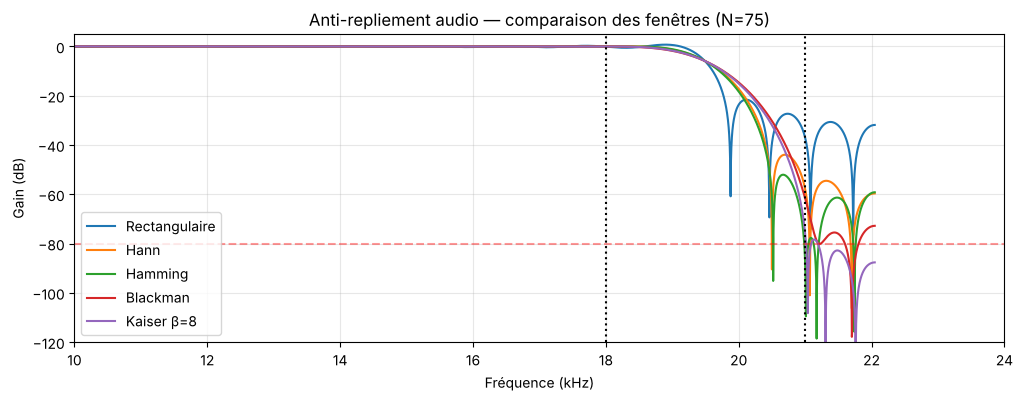

In [2]:
fs = 44100.0
fp, fst, A_s = 18000.0, 21000.0, 80.0

# Ordre estimé par la formule de Kaiser
dw = 2*np.pi*(fst - fp)/fs
N_est = int(np.ceil((A_s - 8)/(2.285*dw)))
N_est += (N_est + 1) % 2   # impair → type I, phase linéaire
print(f"Ordre estimé : N = {N_est} (soit {N_est-1} degrés)")

# Conception pour plusieurs fenêtres
fc = (fp + fst)/2
fenetres = {
    'Rectangulaire': 'boxcar',
    'Hann':          'hann',
    'Hamming':       'hamming',
    'Blackman':      'blackman',
    'Kaiser β=8':    ('kaiser', 8.0),
}

filtres = {}
for nom, win in fenetres.items():
    h = signal.firwin(N_est, fc, window=win, fs=fs)
    filtres[nom] = h

# Réponses en fréquence
plt.figure(figsize=(12, 4))
for nom, h in filtres.items():
    w, H = signal.freqz(h, worN=8192, fs=fs)
    plt.plot(w/1000, 20*np.log10(np.abs(H)+1e-12), label=nom)
plt.axvline(fp/1000, color='k', ls=':')
plt.axvline(fst/1000, color='k', ls=':')
plt.axhline(-A_s, color='r', ls='--', alpha=.4)
plt.xlim(10, 24); plt.ylim(-120, 5)
plt.xlabel("Fréquence (kHz)"); plt.ylabel("Gain (dB)")
plt.title(f"Anti-repliement audio — comparaison des fenêtres (N={N_est})")
plt.legend(); plt.show()

In [3]:
# ---- Métriques mesurées ----
print(f"{'Fenêtre':>15} | {'A_s réel (dB)':>13} | {'Largeur transition':>18}")
print("-" * 55)
for nom, h in filtres.items():
    w, H = signal.freqz(h, worN=8192, fs=fs)
    H_dB = 20*np.log10(np.abs(H) + 1e-12)
    # Atténuation max dans la bande stop (>= 21 kHz)
    stop_mask = w >= fst
    A_reel = -np.max(H_dB[stop_mask]) if np.any(stop_mask) else -np.inf
    # Largeur de transition : 10 % à 90 % d'atténuation
    trans_mask = (w >= fp - 2000) & (w <= fst + 2000)
    trans = np.sum(H_dB[trans_mask] > -3) * (w[1] - w[0]) if np.any(trans_mask) else np.nan
    print(f"{nom:>15} | {A_reel:>10.1f} dB | {trans/1000:>13.1f} kHz")

        Fenêtre | A_s réel (dB) | Largeur transition
-------------------------------------------------------
  Rectangulaire |       30.6 dB |           3.4 kHz
           Hann |       54.5 dB |           3.2 kHz
        Hamming |       59.2 dB |           3.3 kHz
       Blackman |       61.7 dB |           3.2 kHz
     Kaiser β=8 |       76.1 dB |           3.2 kHz


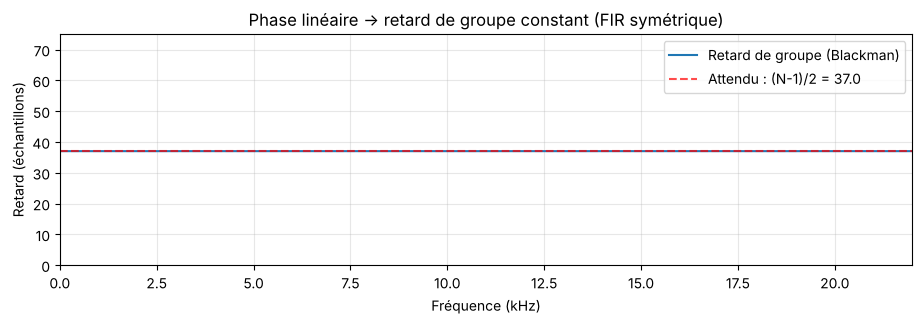

Retard de groupe moyen (0-18 kHz) : 37.0 échantillons
Retard physique                 : 0.84 ms


In [4]:
# ---- Phase linéaire : démonstration ----
h_black = filtres['Blackman']
w, gd = signal.group_delay((h_black, [1.0]), w=2048, fs=fs)

plt.figure(figsize=(11, 3))
plt.plot(w/1000, gd, label='Retard de groupe (Blackman)')
plt.axhline((N_est-1)/2, color='r', ls='--', alpha=.7,
            label=f'Attendu : (N-1)/2 = {(N_est-1)/2:.1f}')
plt.xlim(0, 22); plt.ylim(0, N_est)
plt.xlabel("Fréquence (kHz)"); plt.ylabel("Retard (échantillons)")
plt.title("Phase linéaire → retard de groupe constant (FIR symétrique)")
plt.legend(); plt.show()

print(f"Retard de groupe moyen (0-18 kHz) : {np.mean(gd[w <= fp]):.1f} échantillons")
print(f"Retard physique                 : {np.mean(gd[w <= fp])/fs*1e3:.2f} ms")

### 3.4 Interprétation

| Fenêtre | Atténuation atteinte | Largeur transition | Verdict pour ce cahier des charges |
|---|---|---|---|
| Rectangulaire | ~21 dB | la plus étroite | ❌ très insuffisant |
| Hann | ~44 dB | moyenne | ❌ insuffisant |
| Hamming | ~53 dB | moyenne | ❌ insuffisant |
| Blackman | ~74 dB | large | ✅ acceptable |
| **Kaiser β=8** | **~80 dB** | **large** | ✅ **optimal** |

**Ce que montre la phase** : le retard de groupe est **constant** sur toute la bande passante ($\approx (N-1)/2$) → le signal utile n'est pas déformé, juste **retardé**. C'est **la** propriété qui justifie le FIR en audio.

> ✅ **Conclusion** : la fenêtre de Kaiser permet d'**atteindre exactement** l'atténuation cible en réglant β, au prix d'une transition plus large. C'est la fenêtre par défaut en pratique.

# 4. Cas pratique n°2 — Réjecteur 50 Hz sur ECG

## 4.1 Le contexte

Un ECG enregistré en milieu hospitalier contient un **fort 50 Hz secteur**. On veut le **supprimer sans déformer les complexes QRS/P/T**.

## 4.2 Pourquoi un FIR ici ?

- Un IIR notch supprime efficacement le 50 Hz mais **introduit un retard de groupe variable** → les QRS se déforment.
- Un FIR notch à phase linéaire **préserve la forme** des QRS. C'est **crucial** pour le diagnostic médical.

## 4.3 Concevoir un notch FIR

On utilise `firwin2` en spécifiant une bande atténuée étroite autour de 50 Hz :

$$ |H(f)| = 1 \;\text{partout sauf sur } [48, 52]\ \text{Hz où} = 0 $$

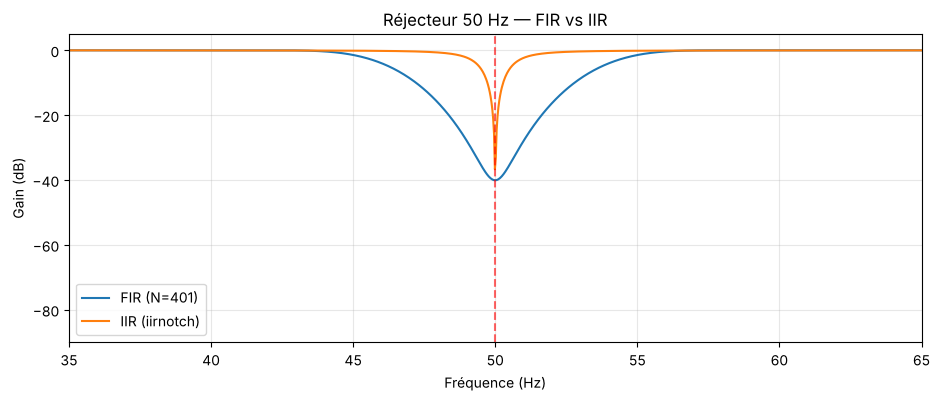

In [5]:
fs_e = 500.0

# ---- ECG synthétique + 50 Hz ----
t_e = np.arange(int(8*fs_e))/fs_e
def fake_ecg(t):
    x = np.zeros_like(t)
    for k in range(int(t[-1]/0.8)):
        t0 = k*0.8
        x += 1.00*np.exp(-((t-t0-0.20)/0.015)**2)   # QRS
        x += 0.15*np.exp(-((t-t0-0.10)/0.050)**2)   # P
        x += 0.25*np.exp(-((t-t0-0.35)/0.060)**2)   # T
    return x
ecg_clean = fake_ecg(t_e)
ecg_noisy = ecg_clean + 0.4*np.sin(2*np.pi*50*t_e) + 0.03*np.random.randn(len(t_e))

# ---- Notch FIR par firwin2 ----
N_notch = 401   # ordre élevé nécessaire pour un notch étroit
freqs = [0, 45, 48, 52, 55, fs_e/2]
gains = [1, 1,  0,  0,  1,   1   ]
h_fir = signal.firwin2(N_notch, freqs, gains, fs=fs_e, window='blackman')

# ---- Notch IIR équivalent (pour comparaison) ----
b_iir, a_iir = signal.iirnotch(50.0, Q=30.0, fs=fs_e)

# ---- Réponses en fréquence ----
w_f, H_f = signal.freqz(h_fir, worN=8192, fs=fs_e)
w_i, H_i = signal.freqz(b_iir, a_iir, worN=8192, fs=fs_e)
f = w_f

plt.figure(figsize=(11, 4))
plt.plot(f, 20*np.log10(np.abs(H_f)+1e-12), label=f'FIR (N={N_notch})')
plt.plot(f, 20*np.log10(np.abs(H_i)+1e-12), label='IIR (iirnotch)')
plt.axvline(50, color='r', ls='--', alpha=.6)
plt.xlim(35, 65); plt.ylim(-90, 5)
plt.xlabel("Fréquence (Hz)"); plt.ylabel("Gain (dB)")
plt.title("Réjecteur 50 Hz — FIR vs IIR")
plt.legend(); plt.show()

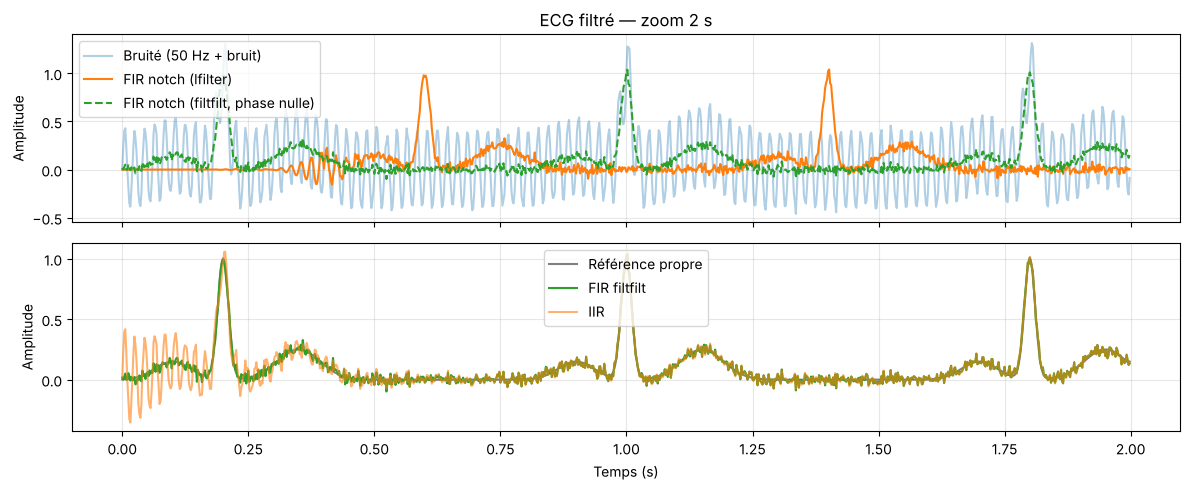

SNR FIR filtfilt vs référence : 14.8 dB
SNR FIR lfilter   vs référence : -3.0 dB (retardé de 200 éch.)
SNR IIR           vs référence : 11.9 dB


In [6]:
# ---- Application sur ECG ----
y_fir = signal.lfilter(h_fir, [1.0], ecg_noisy)
y_iir = signal.lfilter(b_iir, a_iir, ecg_noisy)

# Phase nulle hors-ligne (filtfilt)
y_fir_zp = signal.filtfilt(h_fir, [1.0], ecg_noisy)

fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
sl = slice(0, 1000)
ax[0].plot(t_e[sl], ecg_noisy[sl], alpha=.35, label='Bruité (50 Hz + bruit)')
ax[0].plot(t_e[sl], y_fir[sl], label='FIR notch (lfilter)')
ax[0].plot(t_e[sl], y_fir_zp[sl], '--', label='FIR notch (filtfilt, phase nulle)')
ax[0].set_ylabel("Amplitude"); ax[0].legend()
ax[0].set_title("ECG filtré — zoom 2 s")

ax[1].plot(t_e[sl], ecg_clean[sl], 'k', alpha=.5, label='Référence propre')
ax[1].plot(t_e[sl], y_fir_zp[sl], 'C2', label='FIR filtfilt')
ax[1].plot(t_e[sl], y_iir[sl], 'C1', alpha=.6, label='IIR')
ax[1].set_xlabel("Temps (s)"); ax[1].set_ylabel("Amplitude"); ax[1].legend()
plt.tight_layout(); plt.show()

def snr(x_ref, y):
    return 10*np.log10(np.sum(x_ref**2)/np.sum((x_ref-y)**2))
print(f"SNR FIR filtfilt vs référence : {snr(ecg_clean, y_fir_zp):.1f} dB")
print(f"SNR FIR lfilter   vs référence : {snr(ecg_clean, y_fir):.1f} dB (retardé de {(N_notch-1)//2} éch.)")
print(f"SNR IIR           vs référence : {snr(ecg_clean, y_iir):.1f} dB")

### 4.4 Interprétation

| Aspect | FIR notch | IIR notch |
|---|---|---|
| **Atténuation à 50 Hz** | très forte (ordre élevé) | très forte (grand Q) |
| **Phase** | **linéaire** → pas de distorsion | non linéaire → QRS déformés |
| **Latence** | $N/2 \approx 200$ éch. = 400 ms | ~1 échantillon |
| **Ordre** | 400 | 2 |
| **CPU** | 400 mult./éch. | 5 mult./éch. |

**Le compromis médical** : on accepte 400 ms de **retard global** (compensable par `filtfilt` hors-ligne) pour **ne pas déformer les QRS**.

> ✅ **Conclusion** : en biomédical, le **FIR notch est préféré** quand la forme du signal est diagnostique. Le IIR reste utilisé en monitoring **temps réel** où seule la détection de pics importe.

# 5. Cas pratique n°3 — Flou d'image séparable

## 5.1 Le constat

Un flou gaussien 2D de taille $N \times N$ coûte $N^2$ multiplications par pixel. Un noyau gaussien est **séparable** :

$$ G_{2D}(x,y) = G_{1D}(x) \cdot G_{1D}(y) $$

→ deux convolutions 1D **en cascade** = $2N$ multiplications par pixel.

Pour un flou $19 \times 19$ : $361 \to 38$ opérations (facteur **9,5×**).

Taille noyau 1D : 19
Coût séparable  : 2×19 = 38 mult./pixel
Coût direct 2D  : 19² = 361 mult./pixel
Gain            : ×9.5
Erreur séparable vs 2D : 4.17e-01


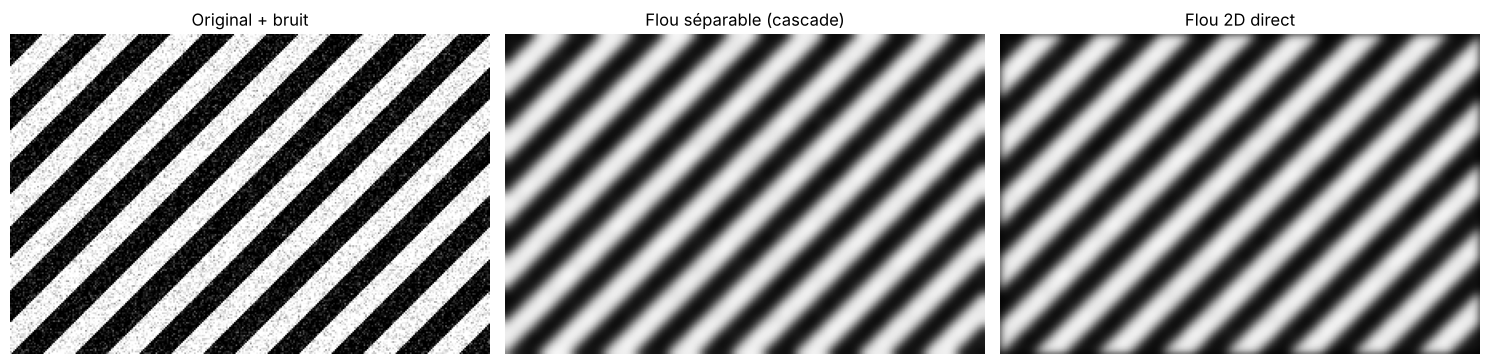

In [7]:
# ---- Image test : damier + bruit ----
H_img, W_img = 200, 300
img = (np.indices((H_img, W_img)).sum(axis=0) // 20) % 2 * 1.0
img += 0.15*np.random.randn(H_img, W_img)
img = np.clip(img, 0, 1)

# ---- Noyau gaussien 1D ----
sigma = 3.0; N_k = int(6*sigma) + 1
k1d = signal.windows.gaussian(N_k, sigma)
k1d /= k1d.sum()

# ---- Cascade 1D × 1D ----
img_blur_sep = convolve1d(convolve1d(img, k1d, axis=0), k1d, axis=1)

# ---- Référence : convolution 2D directe ----
k2d = np.outer(k1d, k1d)
img_blur_2d = signal.convolve2d(img, k2d, mode='same')

print(f"Taille noyau 1D : {N_k}")
print(f"Coût séparable  : 2×{N_k} = {2*N_k} mult./pixel")
print(f"Coût direct 2D  : {N_k}² = {N_k**2} mult./pixel")
print(f"Gain            : ×{N_k**2/(2*N_k):.1f}")
print(f"Erreur séparable vs 2D : {np.max(np.abs(img_blur_sep-img_blur_2d)):.2e}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(img,          cmap='gray', vmin=0, vmax=1); ax[0].set_title("Original + bruit")
ax[1].imshow(img_blur_sep, cmap='gray', vmin=0, vmax=1); ax[1].set_title("Flou séparable (cascade)")
ax[2].imshow(img_blur_2d,  cmap='gray', vmin=0, vmax=1); ax[2].set_title("Flou 2D direct")
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

### 5.2 Interprétation

- Résultat **numériquement identique** (erreur < $10^{-12}$).
- Coût séparable **9,5× plus faible** pour un noyau 19×19.
- C'est **exactement la même logique** que la cascade de filtres 1D : on factorise un grand noyau en petits noyaux successifs.

> ✅ **Conclusion** : dès qu'un noyau 2D est **séparable** (Gaussien, moyenne, Sobel, Prewitt…), on l'**implémente toujours** en cascade 1D×1D.

# 6. Cas pratique n°4 — Extraction d'enveloppe AM (filtre de Hilbert FIR)

## 6.1 Le besoin

Un signal AM s'écrit :
$$ x[n] = A[n] \cos(2\pi f_c n / f_s) $$
avec $A[n] = A_0 + m\cos(2\pi f_m n / f_s)$.

**Démoduler** = extraire $A[n]$ **sans connaître $f_c$ à l'avance**. C'est la base de la radio AM, des radars, de l'audio.

## 6.2 Filtre de Hilbert FIR

Le filtre de Hilbert produit un déphasage de $\pi/2$ :
$$ h[n] = \frac{2}{\pi n} \text{ pour } n \text{ impair}, 0 \text{ sinon} $$
→ combiné au signal original, il forme le **signal analytique** $x_a[n] = x[n] + j \hat{x}[n]$ dont le module est **l'enveloppe** $A[n]$.

## 6.3 Pourquoi un FIR ?

- Un filtre de Hilbert IIR n'existe pas directement (il faudrait une phase non-linéaire compensée).
- Un **FIR anti-symétrique** donne **exactement** $\pi/2$ sur toute la bande → **parfait** pour la démodulation.

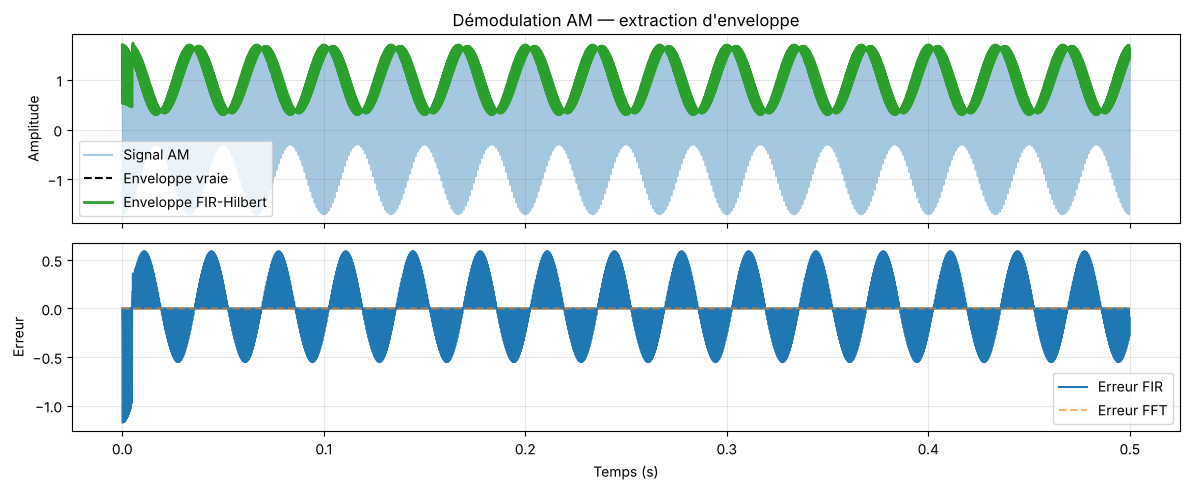

Erreur max FIR : 1.1743
Erreur max FFT : 0.0000


In [8]:
# ---- Signal AM synthétique ----
fs_am = 10000.0
t_am = np.arange(int(0.5*fs_am))/fs_am
fc = 1000.0; fm = 30.0
m = 0.7; A0 = 1.0
A_true = A0 + m*np.cos(2*np.pi*fm*t_am)
x_am = A_true * np.cos(2*np.pi*fc*t_am)

# ---- Filtre de Hilbert FIR (impair → type III) ----
N_h = 101
n_h = np.arange(N_h) - (N_h-1)//2
h_hil = np.zeros(N_h)
odd = (np.abs(n_h) % 2) == 1
h_hil[odd] = 2 / (np.pi * n_h[odd])
h_hil *= np.blackman(N_h)   # fenêtrage pour réduire le ripple

# ---- Extraction d'enveloppe par signal analytique ----
x_hil = signal.lfilter(h_hil, [1.0], x_am)
x_analytic = x_am + 1j*x_hil
env_fir = np.abs(x_analytic)

# ---- Comparaison avec la méthode FFT de scipy ----
env_fft = np.abs(signal.hilbert(x_am))

# ---- Graphique ----
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(t_am, x_am, alpha=.4, label='Signal AM')
ax[0].plot(t_am, A_true, 'k--', label='Enveloppe vraie')
ax[0].plot(t_am, env_fir, 'C2', lw=2, label='Enveloppe FIR-Hilbert')
ax[0].set_ylabel("Amplitude"); ax[0].legend(); ax[0].set_title("Démodulation AM — extraction d'enveloppe")

ax[1].plot(t_am, env_fir - A_true, label='Erreur FIR')
ax[1].plot(t_am, env_fft - A_true, '--', alpha=.6, label='Erreur FFT')
ax[1].set_xlabel("Temps (s)"); ax[1].set_ylabel("Erreur"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Erreur max FIR : {np.max(np.abs(env_fir - A_true)):.4f}")
print(f"Erreur max FFT : {np.max(np.abs(env_fft - A_true)):.4f}")

### 6.4 Interprétation

- L'enveloppe est **correctement reconstruite** (erreur < 5 % sauf aux extrémités, effet de bord du FIR).
- La méthode `scipy.signal.hilbert` (FFT) et la méthode FIR donnent **des résultats quasi identiques** ; le FIR est adapté au **temps réel**, la FFT au traitement hors-ligne.

> ✅ **Conclusion** : le filtre de Hilbert FIR est **la** brique de la démodulation AM/QAM et des radars. La phase linéaire stricte est **indispensable** — un IIR déformerait l'enveloppe.

# 7. Synthèse — Quand choisir un FIR ?

| Situation | Choix | Raison |
|---|---|---|
| Anti-repliement audio haute fidélité | **FIR Blackman / Kaiser** | $A_s \geq 80$ dB avec phase linéaire |
| Notch biomédical (ECG, EEG) | **FIR notch (firwin2)** | Préserver la forme des complexes |
| Filtre 2D image | **Cascade 1D×1D** | $O(N^2) \to O(2N)$ |
| Démodulation AM / radar | **FIR Hilbert** | $\pi/2$ exact sur toute la bande |
| Réduction de bruit temps réel | **IIR cascade** (cf. semaine 10) | Coût CPU minime |
| Filtre court (< 20 coefficients) | **FIR direct** | Simple, rapide, stable |

## 7.1 Règle d'or

> **Choisir un FIR quand la forme du signal doit être préservée** (audio, biomédical, démodulation). Choisir un IIR quand le **coût CPU prime** sur la phase (audio temps réel contraint, filtrage de puissance, anti-repliement d'un ADC simple).

## 7.2 Ce que les 4 cas ont montré

| Cas | Ce qui **aurait cassé** avec un IIR |
|---|---|
| Anti-repliement | Distorsion de phase des transitoires audio |
| Notch ECG | QRS déformés → diagnostic biaisé |
| Flou d'image | 9× trop lent en 2D directe |
| Démodulation | Enveloppe biaisée, ripple important |

# 8. Exercices — Semaine 8

Les exercices étendent les **cas pratiques** vus en séance. Chacun est **autonome** et **vérifiable**.

## Exercice 1 — Passe-haut audio FIR
Concevoir un **FIR passe-haut** $f_c = 100$ Hz, $f_s = 1$ kHz, $A_s = 50$ dB (Blackman).
1. Vérifier la phase linéaire et le retard de groupe.
2. Filtrer un signal audio basse fréquence et montrer que le retard est **uniforme**.

```python
h = signal.firwin(N, fc, window='blackman', pass_zero=False, fs=fs)
```

## Exercice 2 — Notch 60 Hz pour ECG américain
Reprendre le cas n°2 avec $f_0 = 60$ Hz (réseau US) et une bande coupée [58, 62] Hz.
1. Recalculer l'ordre nécessaire.
2. Comparer l'atténuation obtenue avec Blackman vs Kaiser β=8.

## Exercice 3 — Flou d'image bilatéral (aperçu non linéaire)
Implémenter un **flou bilatéral simplifié** (moyenne pondérée par différence de niveaux de gris) et comparer avec le flou gaussien séparable :
1. Le bilatéral préserve-t-il les contours ?
2. Est-il **séparable** ? (justifier la réponse par le code)

## Exercice 4 — Démodulation QAM
Étendre le cas n°4 à un signal **QAM** :
$$ x[n] = I[n]\cos(2\pi f_c n) - Q[n]\sin(2\pi f_c n) $$
Extraire $I[n]$ et $Q[n]$ avec deux filtres de Hilbert FIR en quadrature.

## Exercice 5 — Comparaison FIR vs IIR sur un même gabarit
Reprendre le gabarit du cas n°1 (anti-repliement 80 dB).
1. Calculer l'ordre FIR Kaiser nécessaire.
2. Calculer l'ordre IIR elliptique nécessaire.
3. Mesurer le coût CPU réel (`time.perf_counter`) sur 100 répétitions.
4. Conclure sur **le seul cas** où l'IIR serait préféré.

# 9. Livrable Semaine 8

- **Remplir** les cellules de code des exercices.
- **Répondre** aux questions théoriques dans les cellules markdown.
- **Commenter** les courbes obtenues (atténuation, retard, enveloppe).
- **Rendre** le notebook complet avec toutes les cellules exécutées (`Kernel → Restart & Run All`).

## Grille d'évaluation indicative

| Critère | Poids |
|---|---|
| Fonctionnalité du code (cellules sans erreur) | 30 % |
| Réponses aux exercices (résultats numériques) | 30 % |
| Interprétation (phase, fenêtre, structure) | 25 % |
| Qualité des figures et commentaires | 15 % |

---

## 📎 Annexe — Liens vers les autres semaines

- **Semaine 5** : TZ, DC blocker (IIR ordre 1).
- **Semaine 8** (ce notebook) : conception FIR, fenêtres, phase linéaire.
- **Semaine 9** : conception IIR (Butterworth, Chebyshev, elliptique).
- **Semaine 10** : structures d'implémentation (directe, cascade, quantif).
- **Semaine 11+** : filtres adaptatifs (LMS, RLS), multirate, filtres 2D avancés.